# 05 — Net column energy input (F_net)

F_net = net downward radiation at the top of the atmosphere − net downward
energy flux at the surface (Methods). Positive = the column gains energy.
It is split exactly into six terms:

F_net = F_clr + F_cld + Surf_LW + Surf_SW + Sensible + Latent

with F_clr = clear-sky TOA net (`sraf0 + traf0`), F_cld = all-sky − clear-sky
TOA net (cloud radiative effect), and the four surface terms sign-flipped from
ECHAM's downward-positive convention (`srads`, `trads`, `ahfs`, `ahfl`).

Same structure as `04`: climatology → climatology table → quick check →
all events → analysis table → anomaly maps. The W−E contrast
(`westminuseast_F_net`) is the quantity used in Figure 2c and the
supplementary analysis (`11`).

## Step 0 — sign check

 Over the open warm-pool ocean, downward-positive fluxes must give: net shortwave > 0
 (TOA and surface), net longwave < 0 (TOA and surface), latent and sensible heat < 0
 (the ocean loses heat). A wrong sign here means the sign flips in `flux_components` are wrong.

In [10]:
import xarray as xr
import numpy as np
import config as cfg

check_ds = xr.open_dataset(cfg.CLIMATOLOGY_BOT_PATH)
CHECK_BOX = dict(lat=slice(-10, 10), lon=slice(140, 180))   # western Pacific warm pool
EXPECTED_SIGN = {"srad0": +1, "sraf0": +1, "srads": +1,     # net shortwave: down
                 "trad0": -1, "traf0": -1, "trads": -1,     # net longwave: up
                 "ahfl": -1, "ahfs": -1}                    # latent, sensible: up
for var, sign in EXPECTED_SIGN.items():
    value = box_mean(check_ds[var].mean("time"), CHECK_BOX)
    ok = np.sign(value) == sign
    print(f"{var:6s} {value:8.1f} W/m2   expected {'+' if sign > 0 else '-'}   {'ok' if ok else 'WRONG SIGN'}")
    assert ok, f"{var} does not follow the downward-positive convention"

srad0     332.4 W/m2   expected +   ok
sraf0     375.3 W/m2   expected +   ok
srads     235.6 W/m2   expected +   ok
trad0    -239.8 W/m2   expected -   ok
traf0    -280.3 W/m2   expected -   ok
trads     -49.8 W/m2   expected -   ok
ahfl     -125.6 W/m2   expected -   ok
ahfs      -19.5 W/m2   expected -   ok


In [2]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Rectangle

WEST_BOX = dict(lat=slice(-5, 5), lon=slice(80, 160))
EAST_BOX = dict(lat=slice(-5, 5), lon=slice(200, 280))
RUN_SUFFIX = {"Full Run": "FULL", "Uniform Run": "UNIFORM", "Pattern Run": "PATTERN"}
FLUX_COMPONENTS = ["F_clr", "F_cld", "Surf_LW", "Surf_SW", "Sensible", "Latent", "F_net"]
REQUIRED_VARS = {"sraf0", "traf0", "srad0", "trad0", "srads", "trads", "ahfl", "ahfs"}
FNET_MAP_VMIN, FNET_MAP_VMAX = -150, 150   # <- colour limits (W/m2) of the absolute F_net maps (Steps 1 and 3)


def box_mean(field, box):
    """Cos-latitude weighted box mean; works for ascending or descending latitude."""
    lat_lo, lat_hi = box["lat"].start, box["lat"].stop
    lat_slice = slice(lat_lo, lat_hi) if field.lat[0] < field.lat[-1] else slice(lat_hi, lat_lo)
    sub = field.sel(lat=lat_slice, lon=box["lon"])
    weights = np.cos(np.deg2rad(sub.lat))
    return sub.weighted(weights).mean(["lat", "lon"]).item()


def flux_components(ds):
    """Time-mean F_net and its six terms (W/m2), all positive = energy into the atmosphere."""
    F_clr = ds["sraf0"] + ds["traf0"]               # TOA clear-sky net (downward +)
    F_all = ds["srad0"] + ds["trad0"]               # TOA all-sky net
    F_cld = F_all - F_clr                           # cloud radiative effect at TOA
    Surf_SW, Surf_LW = -ds["srads"], -ds["trads"]   # surface net radiation, sign-flipped
    Sensible, Latent = -ds["ahfs"], -ds["ahfl"]     # surface turbulent fluxes, sign-flipped
    F_net = F_clr + F_cld + Surf_SW + Surf_LW + Sensible + Latent
    fields = {"F_clr": F_clr, "F_cld": F_cld, "Surf_LW": Surf_LW, "Surf_SW": Surf_SW,
              "Sensible": Sensible, "Latent": Latent, "F_net": F_net}
    return {name: da.mean("time") if "time" in da.dims else da for name, da in fields.items()}


def event_dir(event):
    return cfg.ECHAM_OUTPUT_ELNINO_DIR if event == "El Niño" else cfg.ECHAM_OUTPUT_LANINA_DIR


def show_with_boxes(field, title, vmin=FNET_MAP_VMIN, vmax=FNET_MAP_VMAX):
    plt.figure(figsize=(9, 4))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines()
    field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=vmin, vmax=vmax)
    for box, color in [(WEST_BOX, "red"), (EAST_BOX, "blue")]:
        lon0, lon1 = box["lon"].start, box["lon"].stop
        lat0, lat1 = box["lat"].start, box["lat"].stop
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, edgecolor=color, facecolor="none",
                               linestyle="--", linewidth=1.5, transform=ccrs.PlateCarree()))
    plt.title(title)
    plt.show()


def restrict_tropics(field, lat_bound=30):
    lat_slice = slice(-lat_bound, lat_bound) if field.lat[0] < field.lat[-1] else slice(lat_bound, -lat_bound)
    return field.sel(lat=lat_slice)


def show_anomaly_map(field, title, levels, cbar_ticks=None, extend="neither", label="F_net anomaly (W/m²)"):
    plt.figure(figsize=(9, 4))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines()
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4)
    pcm = field.plot.contourf(ax=ax, levels=levels, cmap="RdBu_r", extend=extend,
                              add_colorbar=False, transform=ccrs.PlateCarree())
    plt.colorbar(pcm, ax=ax, orientation="vertical", label=label, ticks=cbar_ticks, shrink=0.8)
    plt.title(title)
    plt.show()

## Step 1 — climatology (control run, `cfg.CLIM_PERIOD`)

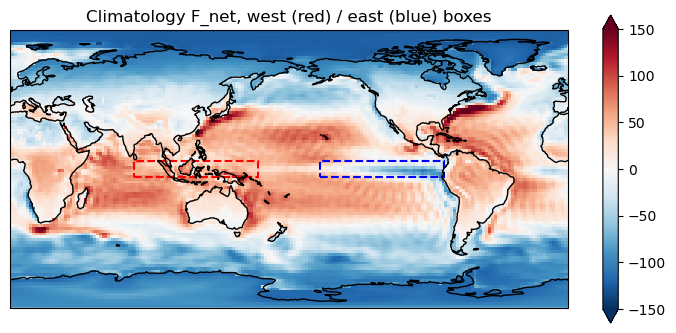

climatology F_clr: west-east =    9.941 W/m2
climatology F_cld: west-east =   35.034 W/m2
climatology Surf_LW: west-east =    5.062 W/m2
climatology Surf_SW: west-east =    1.788 W/m2
climatology Sensible: west-east =    2.187 W/m2
climatology Latent: west-east =   15.253 W/m2
climatology F_net: west-east =   69.265 W/m2


In [3]:
climatology_ds = xr.open_dataset(cfg.CLIMATOLOGY_BOT_PATH)
if not REQUIRED_VARS.issubset(climatology_ds.variables):
    raise KeyError(f"climatology file missing {REQUIRED_VARS.difference(climatology_ds.variables)}")
if cfg.CLIM_PERIOD is not None:
    climatology_ds = climatology_ds.sel(time=slice(*cfg.CLIM_PERIOD))

climatology = flux_components(climatology_ds)   # dict: component -> time-mean field

show_with_boxes(climatology["F_net"], "Climatology F_net, west (red) / east (blue) boxes")

clim_values = {}
for comp, field in climatology.items():
    east = box_mean(field, EAST_BOX)
    west = box_mean(field, WEST_BOX)
    clim_values[f"east_mean_{comp}"] = east
    clim_values[f"west_mean_{comp}"] = west
    clim_values[f"eastminuswest_{comp}"] = east - west
    clim_values[f"westminuseast_{comp}"] = west - east
    print(f"climatology {comp}: west-east = {west - east:8.3f} W/m2")

## Step 2 — write the climatology to the climatology table

In [4]:
def update_climatology_csv(new_values):
    if os.path.exists(cfg.CLIMATOLOGY_CSV_PATH):
        clim_df = pd.read_csv(cfg.CLIMATOLOGY_CSV_PATH)
        if len(clim_df) == 0:
            clim_df = pd.DataFrame([{}])
    else:
        clim_df = pd.DataFrame([{}])
    for col, val in new_values.items():
        clim_df.loc[0, col] = val
    os.makedirs(cfg.ANALYSIS_DIR, exist_ok=True)
    clim_df.to_csv(cfg.CLIMATOLOGY_CSV_PATH, index=False)


update_climatology_csv(clim_values)
print("saved", cfg.CLIMATOLOGY_CSV_PATH)

saved /work/mh1421/m301201/repo/walker-tug-of-war/data/complete_climatology.csv


## Step 3 — quick check: one event, all three runs

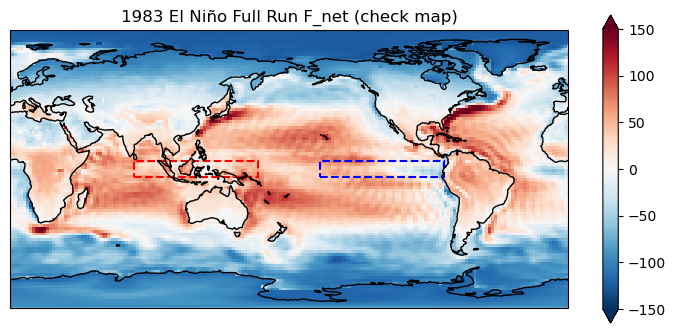

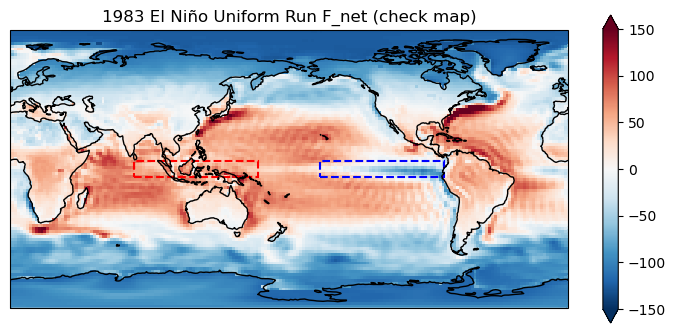

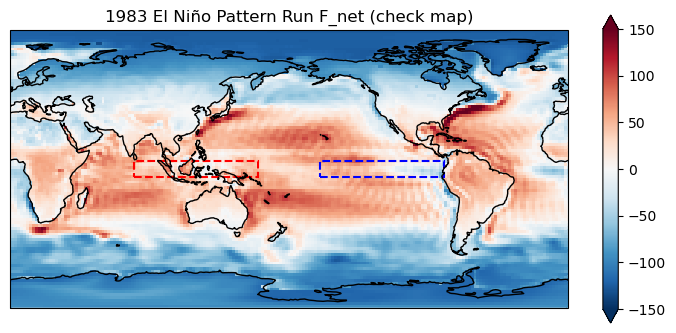

In [5]:
CHECK_EVENT_YEAR = 1983          # <- any event year
CHECK_EVENT_TYPE = "El Niño"     # must match the folder the year's data lives in

for run in ["Full Run", "Uniform Run", "Pattern Run"]:
    check_path = os.path.join(event_dir(CHECK_EVENT_TYPE), f"{CHECK_EVENT_YEAR}_{RUN_SUFFIX[run]}_echam6_BOT_mm_1976-1999.nc")
    if os.path.exists(check_path):
        check_fnet = flux_components(xr.open_dataset(check_path))["F_net"]
        show_with_boxes(check_fnet, f"{CHECK_EVENT_YEAR} {CHECK_EVENT_TYPE} {run} F_net (check map)")
    else:
        print(f"missing {check_path} -- change CHECK_EVENT_YEAR/CHECK_EVENT_TYPE above")

## Step 4 — all events → analysis table

In [6]:
df = pd.read_csv(cfg.ANALYSIS_CSV_PATH)

for comp in FLUX_COMPONENTS:
    for col in [f"east_mean_{comp}", f"west_mean_{comp}", f"eastminuswest_{comp}", f"westminuseast_{comp}"]:
        if col not in df.columns:
            df[col] = np.nan

for _, row in df.drop_duplicates(subset=["Year", "Run"]).iterrows():
    year, run, event = row["Year"], row["Run"], row["Event"]
    path = os.path.join(event_dir(event), f"{year}_{RUN_SUFFIX[run]}_echam6_BOT_mm_1976-1999.nc")
    if not os.path.exists(path):
        print(f"missing file for {year} {run} -- skipping")
        continue

    ds = xr.open_dataset(path)
    if not REQUIRED_VARS.issubset(ds.variables):
        print(f"missing variables in {path} -- skipping")
        continue

    mask = (df["Year"] == year) & (df["Run"] == run)
    for comp, field in flux_components(ds).items():
        east = box_mean(field, EAST_BOX)
        west = box_mean(field, WEST_BOX)
        df.loc[mask, f"east_mean_{comp}"] = east
        df.loc[mask, f"west_mean_{comp}"] = west
        df.loc[mask, f"eastminuswest_{comp}"] = east - west
        df.loc[mask, f"westminuseast_{comp}"] = west - east
    print(f"{year} {run}: F_net west-east = {df.loc[mask, 'westminuseast_F_net'].iloc[0]:.2f} W/m2")

df.to_csv(cfg.ANALYSIS_CSV_PATH, index=False)
print("saved", cfg.ANALYSIS_CSV_PATH)

1983 Full Run: F_net west-east = 16.00 W/m2
1983 Uniform Run: F_net west-east = 73.08 W/m2
1983 Pattern Run: F_net west-east = 10.79 W/m2
1984 Full Run: F_net west-east = 79.68 W/m2
1984 Uniform Run: F_net west-east = 66.85 W/m2
1984 Pattern Run: F_net west-east = 78.32 W/m2
1985 Full Run: F_net west-east = 86.24 W/m2
1985 Uniform Run: F_net west-east = 65.63 W/m2
1985 Pattern Run: F_net west-east = 87.42 W/m2
1986 Full Run: F_net west-east = 81.17 W/m2
1986 Uniform Run: F_net west-east = 66.43 W/m2
1986 Pattern Run: F_net west-east = 86.11 W/m2
1987 Full Run: F_net west-east = 47.24 W/m2
1987 Uniform Run: F_net west-east = 69.61 W/m2
1987 Pattern Run: F_net west-east = 47.47 W/m2
1988 Full Run: F_net west-east = 52.76 W/m2
1988 Uniform Run: F_net west-east = 70.61 W/m2
1988 Pattern Run: F_net west-east = 51.68 W/m2
1989 Full Run: F_net west-east = 96.27 W/m2
1989 Uniform Run: F_net west-east = 63.12 W/m2
1989 Pattern Run: F_net west-east = 99.18 W/m2
1992 Full Run: F_net west-east = 4

## Step 5 — quick check: anomaly maps (run − climatology), 30°S–30°N

`COMPONENT` selects which term to map ("F_net" or any of the six terms).

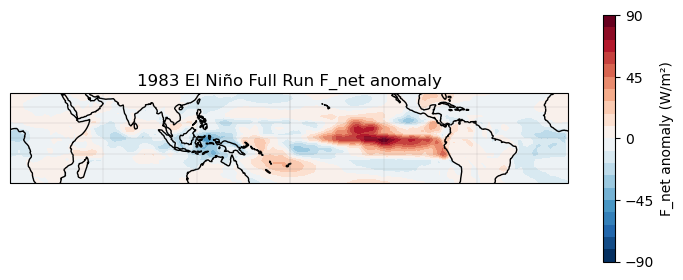

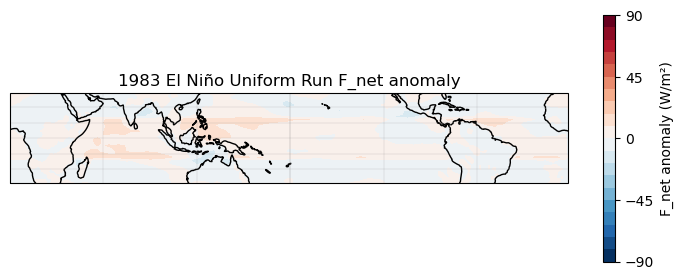

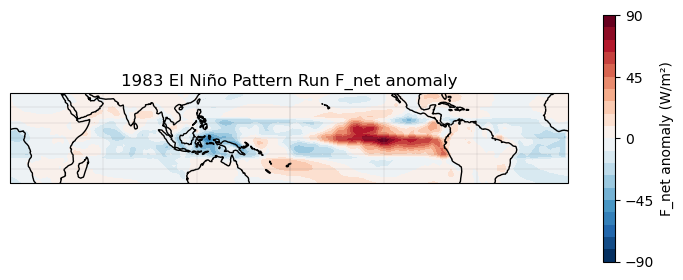

In [7]:
COMPONENT = "F_net"   # <- "F_net", "F_clr", "F_cld", "Surf_LW", "Surf_SW", "Sensible" or "Latent"
VMIN = None           # <- explicit limits in W/m2, e.g. VMIN = -60, VMAX = 60; None = automatic
VMAX = None
N_LEVELS = 21
TICK_STEP = 10        # W/m2, used to round VMAX up to a clean value
N_TICKS = 5

anomalies = {}
for run in ["Full Run", "Uniform Run", "Pattern Run"]:
    check_path = os.path.join(event_dir(CHECK_EVENT_TYPE), f"{CHECK_EVENT_YEAR}_{RUN_SUFFIX[run]}_echam6_BOT_mm_1976-1999.nc")
    if not os.path.exists(check_path):
        print(f"missing {check_path} -- change CHECK_EVENT_YEAR/CHECK_EVENT_TYPE above")
        continue
    event_field = flux_components(xr.open_dataset(check_path))[COMPONENT]
    anomalies[run] = restrict_tropics(event_field - climatology[COMPONENT], 30)

if VMAX is None:
    data_vmax = float(max(np.abs(f).max() for f in anomalies.values()))
    VMAX = TICK_STEP * np.ceil(data_vmax / TICK_STEP)
if VMIN is None:
    VMIN = -VMAX

levels = np.linspace(VMIN, VMAX, N_LEVELS)
cbar_ticks = np.linspace(VMIN, VMAX, N_TICKS)

for run, field in anomalies.items():
    show_anomaly_map(field, f"{CHECK_EVENT_YEAR} {CHECK_EVENT_TYPE} {run} {COMPONENT} anomaly",
                     levels, cbar_ticks, label=f"{COMPONENT} anomaly (W/m²)")

## Step 6 — quick check: which terms carry the change in the W−E contrast?

Because F_net is a sum, its anomaly splits exactly:
ΔF_net,W−E = Σ ΔF_i,W−E, with Δ = run − climatology. Printed for the check
event; the 23-event version is supplementary Figure S2 (`11`).

In [8]:
COMPONENTS_MINUS_FNET = [c for c in FLUX_COMPONENTS if c != "F_net"]
clim_we = {c: clim_values[f"westminuseast_{c}"] for c in FLUX_COMPONENTS}

for run in ["Full Run", "Uniform Run", "Pattern Run"]:
    row = df[(df["Year"] == CHECK_EVENT_YEAR) & (df["Run"] == run)].iloc[0]
    d_total = row["westminuseast_F_net"] - clim_we["F_net"]
    print(f"\n{CHECK_EVENT_YEAR} {run}: ΔF_net,W-E = {d_total:+.2f} W/m2")
    changes = {c: row[f"westminuseast_{c}"] - clim_we[c] for c in COMPONENTS_MINUS_FNET}
    for comp, val in sorted(changes.items(), key=lambda kv: -abs(kv[1])):
        print(f"  {comp:9s} {val:+7.2f} W/m2  ({100 * val / d_total:6.1f} % of ΔF_net)")


1983 Full Run: ΔF_net,W-E = -53.27 W/m2
  F_cld      -19.36 W/m2  (  36.3 % of ΔF_net)
  Latent     -18.20 W/m2  (  34.2 % of ΔF_net)
  F_clr       -8.39 W/m2  (  15.8 % of ΔF_net)
  Surf_SW     -7.20 W/m2  (  13.5 % of ΔF_net)
  Sensible    -0.62 W/m2  (   1.2 % of ΔF_net)
  Surf_LW     +0.50 W/m2  (  -0.9 % of ΔF_net)

1983 Uniform Run: ΔF_net,W-E = +3.82 W/m2
  Latent      +1.61 W/m2  (  42.2 % of ΔF_net)
  Surf_SW     +1.57 W/m2  (  41.0 % of ΔF_net)
  F_clr       +0.39 W/m2  (  10.1 % of ΔF_net)
  Sensible    +0.28 W/m2  (   7.3 % of ΔF_net)
  Surf_LW     -0.07 W/m2  (  -1.9 % of ΔF_net)
  F_cld       +0.05 W/m2  (   1.3 % of ΔF_net)

1983 Pattern Run: ΔF_net,W-E = -58.48 W/m2
  F_cld      -20.25 W/m2  (  34.6 % of ΔF_net)
  Latent     -20.16 W/m2  (  34.5 % of ΔF_net)
  F_clr       -9.24 W/m2  (  15.8 % of ΔF_net)
  Surf_SW     -8.54 W/m2  (  14.6 % of ΔF_net)
  Sensible    -0.82 W/m2  (   1.4 % of ΔF_net)
  Surf_LW     +0.54 W/m2  (  -0.9 % of ΔF_net)
